In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Student Social Media And Mental Health Impact.csv')

In [3]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [5]:
df.shape

(5000, 13)

In [9]:
df.dtypes

,0
Age,int64
Gender,object
Country,object
Academic_Level,object
Most_Used_Platform,object
Purpose_Of_Use,object
Avg_Daily_Usage_Hours,float64
Daily_Unlocks,int64
Study_Hours,float64
Physical_Activity_Hours,float64


In [11]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [12]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [13]:
df.duplicated().sum()

np.int64(2)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

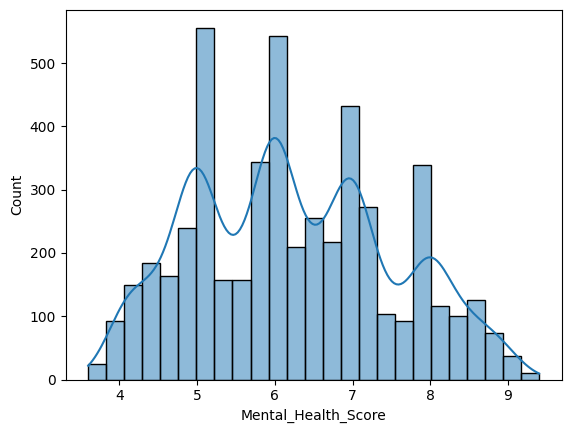

In [16]:
sns.histplot(df['Mental_Health_Score'],kde=True)

<Axes: >

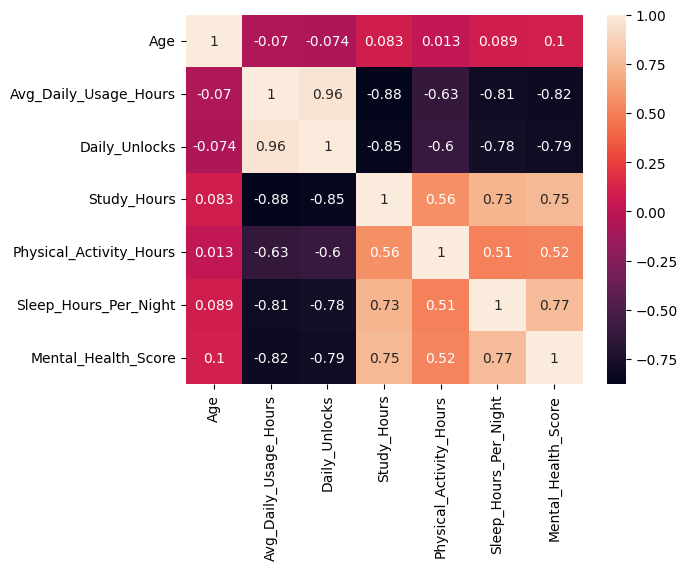

In [18]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

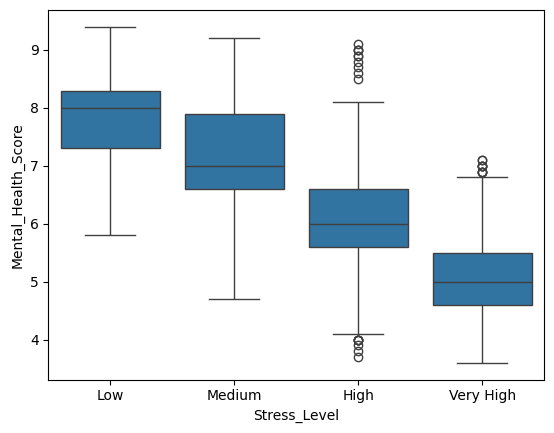

In [21]:
order = ['Low','Medium','High','Very High']
sns.boxplot(x='Stress_Level', y='Mental_Health_Score',data=df, order=order)

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

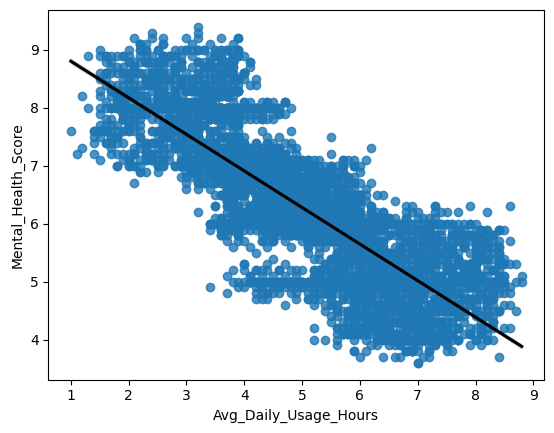

In [29]:
sns.regplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score', data=df, line_kws={'color': 'black'})

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

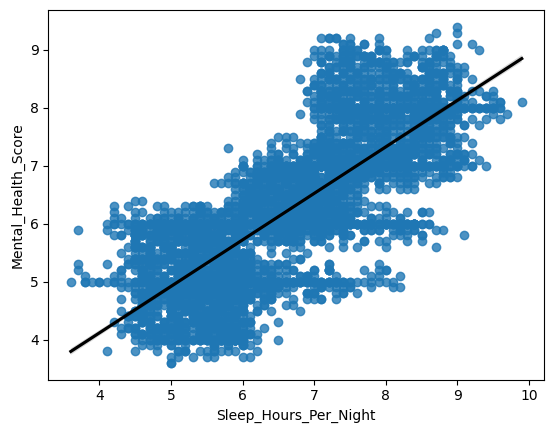

In [27]:
sns.regplot(x='Sleep_Hours_Per_Night', y='Mental_Health_Score', data=df, line_kws={'color': 'black'})

In [30]:
df['Most_Used_Platform'].value_counts()

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,523
YouTube,491
Twitter,462
Snapchat,420
WhatsApp,175
LINE,50


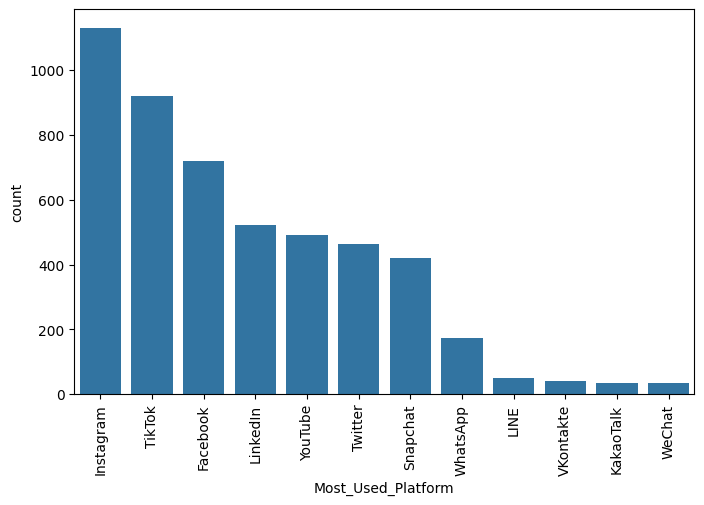

In [39]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['Most_Used_Platform'], order=df['Most_Used_Platform'].value_counts().index)
plt.xticks(rotation=90)
plt.show()

In [41]:
num_features = df.select_dtypes(include='number')
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


In [42]:
df = df.drop_duplicates()

In [46]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [47]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

/tmp/ipykernel_627/595824244.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)


In [49]:
num_columns = df.select_dtypes(include='number')
num_columns.skew()
# near to 0 -> Centralized (0.01, 0.002)
# negative -> Left Skewed (-1.56)
# poistive (greater than 0) -> Right Skewed (1.256)

,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


In [65]:
df['Country'].value_counts()

,count
Country,
Other,1879
India,389
USA,354
Canada,230
Australia,198
...,...
Armenia,1
Bosnia,1
Kuwait,1


In [57]:
top_country = df['Country'].value_counts().index[:10].tolist()
top_country

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [58]:
def group_country(Country):
  if Country in top_country:
    return Country
  else:
    return 'Other'

In [59]:
df['Group_Country'] = df['Country'].apply(group_country)

/tmp/ipykernel_627/924677688.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group_Country'] = df['Country'].apply(group_country)


In [60]:
df['Group_Country'].value_counts()

,count
Group_Country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


In [66]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'Group_Country'],
      dtype='object')

In [92]:
from sklearn.model_selection import train_test_split
skwed_colmn = ['Study_Hours']
numeric_colmn = ["Age","Avg_Daily_Usage_Hours","Daily_Unlocks","Physical_Activity_Hours","Sleep_Hours_Per_Night"]
ordinal_colmn = ['Stress_Level']
norminal_colmn = ['Gender','Academic_Level','Most_Used_Platform','Purpose_Of_Use','Group_Country']

features_colmn = skwed_colmn + numeric_colmn + ordinal_colmn + norminal_colmn

X = df[features_colmn]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [93]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

skwed_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

numeric_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler())
])

ordinal_pipeline = Pipeline(steps=[
    ('encoder', OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
])

nominal_pipeline = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('Skwed_Pipeline', skwed_pipeline, skwed_colmn),
    ('Numeric_Pipeline', numeric_pipeline, numeric_colmn),
    ('Ordinal_Pipeline', ordinal_pipeline, ordinal_colmn),
    ('Normal_Pipeline', nominal_pipeline, norminal_colmn)
])

In [94]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)


lr_pred_train = lr_pipeline.predict(X_train)
lr_r2score_train = r2_score(y_train,lr_pred_train)


lr_r2score = r2_score(y_test,lr_pred)
lr_mae = mean_absolute_error(y_test,lr_pred)

print(f'Accuracy of Training : {lr_r2score_train}')
print(f'Accuracy of Testing : {lr_r2score}')
print(f'Mean Absolute Error : {lr_mae}')


Accuracy of Training : 0.7236771199387538
Accuracy of Testing : 0.7397944617433021
Mean Absolute Error : 0.5361775634720181


In [102]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprossing', preprocessor),
    ('random_forest', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)


rf_pred_train = rf_pipeline.predict(X_train)
rf_r2score_trining = r2_score(y_train, rf_pred_train)


rf_r2score = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)

print(f'Training Accuracy : {rf_r2score_trining}')
print(f'Testing Accuracy : {rf_r2score}')
print(f'Mean Absolute Error : {rf_mae}')


Training Accuracy : 0.9808287942404612
Testing Accuracy : 0.8775888638668996
Mean Absolute Error : 0.34722113333333343


In [110]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random_forest__n_estimators' : [100,200,300],
    'random_forest__max_depth' : [5,10,15],
    'random_forest__min_samples_split' : [2,5,10],
    'random_forest__min_samples_leaf' : [1,2,4]
}

random_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_grid,
    n_iter = 15,
    cv = 5,
    scoring = 'r2',
    random_state = 42,
    n_jobs = -1
)

random_search.fit(X_train,y_train)


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprossing',
                                              ColumnTransformer(transformers=[('Skwed_Pipeline',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('Numeric_Pipeline',
                                                                               Pipeline(steps=[('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'Avg_Daily_Usage_Hours',
                                                                                'Daily_Unlocks',...
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use',
                                                                                'Group_Country'])])),
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'random_forest__max_depth': [5, 10, 15],
                                        'random_forest__min_samples_leaf': [1,
                                                                            2,
                                                                            4],
                                        'random_forest__min_samples_split': [2,
                                                                             5,
                                                                             10],
                                        'random_forest__n_estimators': [100,
                                                                        200,
                                                                        300]},
                   random_state=42, scoring='r2')

In [111]:
random_search.best_params_


{'random_forest__n_estimators': 200,
 'random_forest__min_samples_split': 5,
 'random_forest__min_samples_leaf': 2,
 'random_forest__max_depth': 15}

In [113]:
rf_best_pipeline = random_search.best_estimator_
rf_best_pred = rf_best_pipeline.predict(X_test)

print(f'R2 Score for Random Forest after hyperparameter tuning: {r2_score(y_test, rf_best_pred)}')
print(f'Mean Absolute Error for Random Forest after hyperparameter tuning: {mean_absolute_error(y_test, rf_best_pred)}')

R2 Score for Random Forest after hyperparameter tuning: 0.8650140569761653
Mean Absolute Error for Random Forest after hyperparameter tuning: 0.3689015766630922


In [114]:
from sklearn.metrics import mean_squared_error

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2score, rf_r2score, rf_tuned_r2],
    'Training R2': [lr_r2score_train, rf_r2score_trining, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)


                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.877589     0.980829  0.347221  0.463681
2    Random Forest (tuned)  0.865014     0.954703  0.368902  0.486915


In [115]:
import joblib
joblib.dump(rf_pipeline,'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']